# Robot-Assisted Farming: performance analysis

This notebook compares the operation modes of the multi-agent system using its KPIs.
Every number comes from `experiments.py`: 10 seeds (0–9) × 1000 steps per configuration, on the
default layout with 4 pickers, 2 drones and storage for 10 strawberries per picker. Runs are
deterministic for a given seed, so re-running gives the same results.

**Configurations**

| Configuration | Crops age & regrow | How pickers find crops |
|---|---|---|
| Basic | no | random exploration; drones hover over crops but cannot signal |
| Extended (broadcast) | yes | drones broadcast each crop area to every picker |
| Extended (direct) | yes | drones message the nearest picker with free storage |
| Novel (Contract Net) | yes | drones auction each crop area; pickers bid their estimated cost |

**KPIs**

* **Harvest rate**: picked ÷ (picked + wasted). The share of ripened strawberries that were saved. *Higher is better.*
* **Energy per strawberry**: battery energy used by all robots ÷ strawberries delivered. *Lower is better.*
* **Mean pick latency**: steps between a crop ripening and being picked. *Lower is better.*
* **Messages sent**: communication load (a broadcast counts once). *Lower is cheaper.*
* Delivered, wasted and picker utilisation are also recorded.

In [1]:
import os
import pandas as pd
from IPython.display import Image, display

import experiments as ex

RESULTS = os.path.join("..", "results")
final_path = os.path.join(RESULTS, "final_kpis.csv")
if not os.path.exists(final_path):          # first run: generate the data (takes ~1-2 minutes)
    os.makedirs(RESULTS, exist_ok=True)
    finals, series = ex.run_all(seeds=10, steps=1000)
    finals.to_csv(final_path, index=False)
    series.to_csv(os.path.join(RESULTS, "timeseries.csv"), index=False)

finals = pd.read_csv(final_path)
series = pd.read_csv(os.path.join(RESULTS, "timeseries.csv"))
len(finals), finals["Config"].unique().tolist()

(40,
 ['Basic',
  'Extended (broadcast)',
  'Extended (direct)',
  'Novel (Contract Net)'])

## 1. Summary table (mean and standard deviation over 10 seeds)

In [2]:
order = [c[0] for c in ex.CONFIGS]
summary = finals.groupby("Config")[ex.KPIS].agg(["mean", "std"]).reindex(order).round(2)
summary

Delivered        Wasted        Harvest rate        \
                          mean    std   mean    std         mean   std   
Config                                                                   
Basic                     69.2   3.79    0.0   0.00         1.00  0.00   
Extended (broadcast)     277.8  29.36  215.9  21.26         0.58  0.04   
Extended (direct)        308.3  26.39  199.0  17.40         0.62  0.04   
Novel (Contract Net)     296.0  20.81  202.6  15.48         0.61  0.02   

                     Energy per strawberry       Mean pick latency         \
                                      mean   std              mean    std   
Config                                                                      
Basic                                16.90  5.03            155.26  38.13   
Extended (broadcast)                  6.69  0.72             57.55   5.41   
Extended (direct)                     5.81  0.35             58.28   5.11   
Novel (Contract Net)                  5.87  0.41             58.08   2.46   

                     Picker utilisation       Messages sent         
                                   mean   std          mean    std  
Config                                                              
Basic                              0.92  0.01           0.0   0.00  
Extended (broadcast)               0.90  0.02          99.6   7.86  
Extended (direct)                  0.83  0.04          93.2   8.13  
Novel (Contract Net)               0.79  0.05         847.5  70.48

## 2. KPI comparison

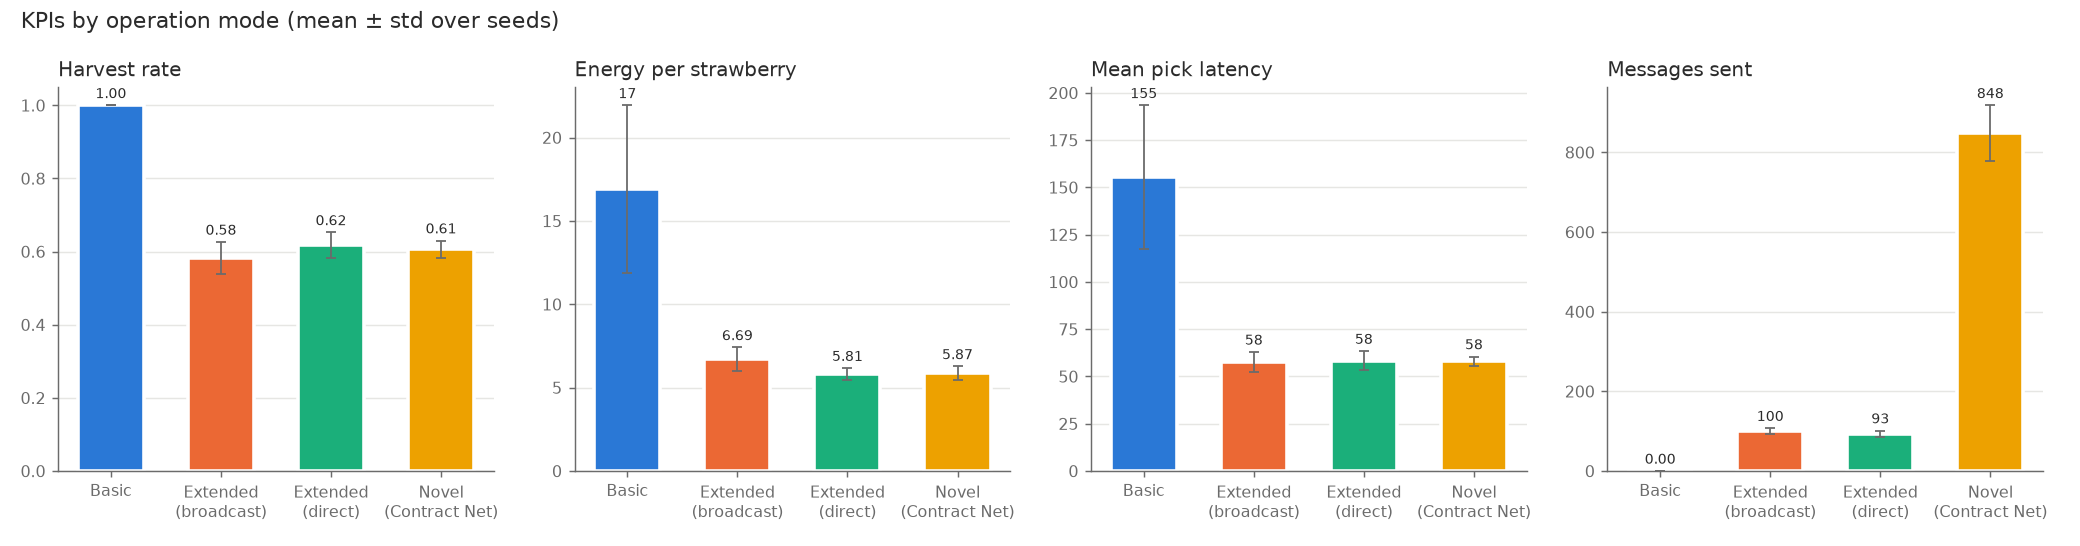

In [3]:
ex.plot_kpi_bars(finals, os.path.join(RESULTS, "kpi_comparison.png"))
display(Image(os.path.join(RESULTS, "kpi_comparison.png")))

## 3. Harvest and waste over time (modes with ageing crops)

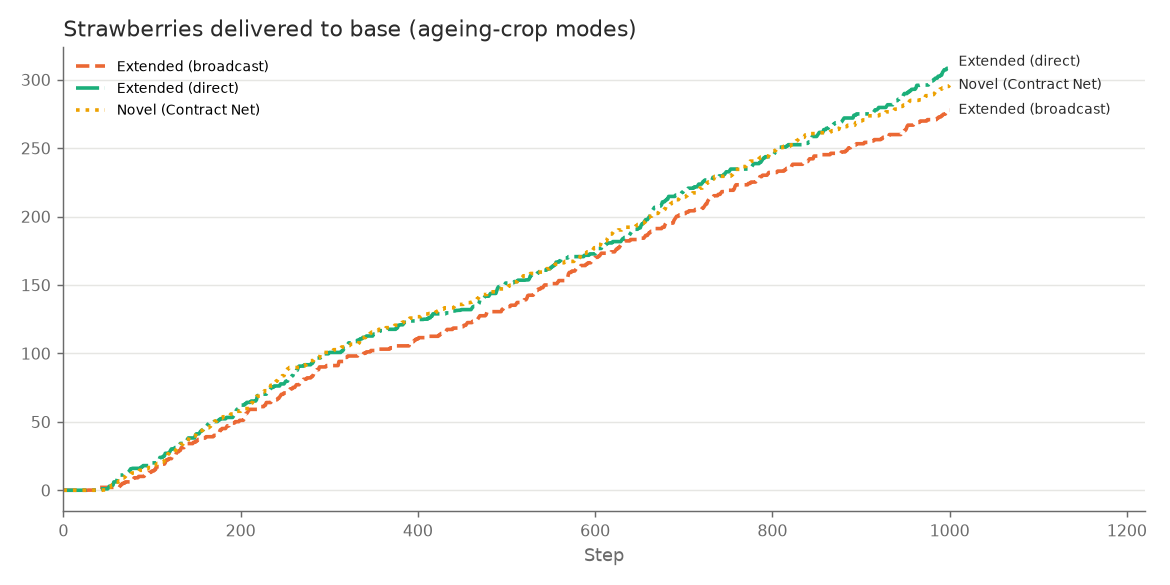

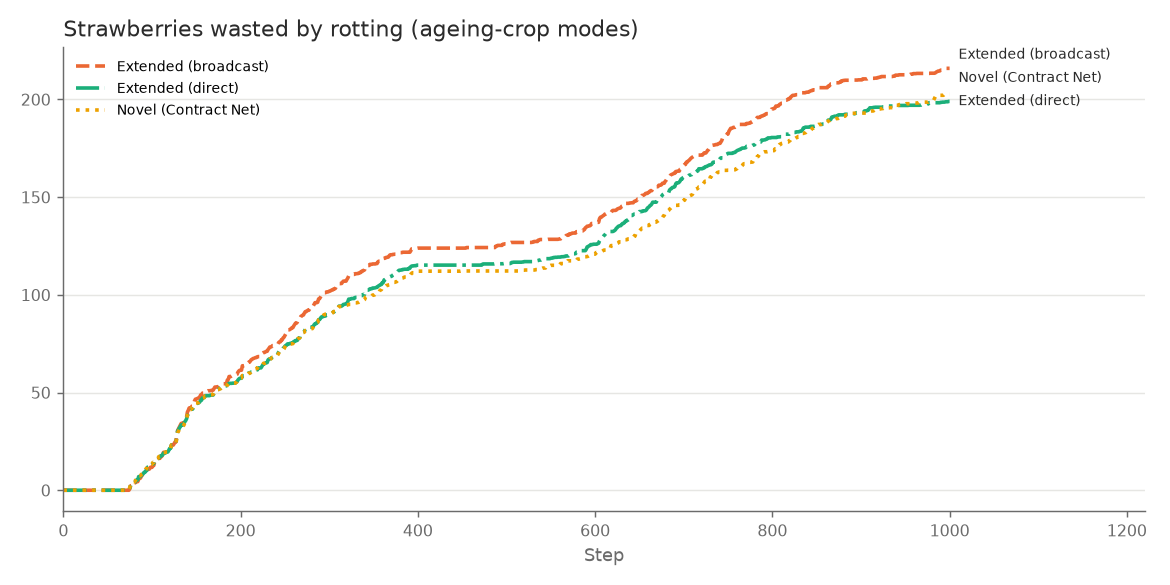

In [4]:
ageing = series[series["Config"] != "Basic"]
ex.plot_over_time(ageing, "Delivered", os.path.join(RESULTS, "delivered_over_time.png"),
                  "Strawberries delivered to base (ageing-crop modes)")
ex.plot_over_time(ageing, "Wasted", os.path.join(RESULTS, "wasted_over_time.png"),
                  "Strawberries wasted by rotting (ageing-crop modes)")
display(Image(os.path.join(RESULTS, "delivered_over_time.png")))
display(Image(os.path.join(RESULTS, "wasted_over_time.png")))

## 4. Sensitivity: how many pickers does the farm need?

Generated with `python experiments.py --sweep` (5 seeds per point).

Pickers,2,4,6,8
Config,,,,
Extended (broadcast),0.424,0.589,0.695,0.743
Extended (direct),0.404,0.614,0.721,0.746
Novel (Contract Net),0.418,0.604,0.682,0.729


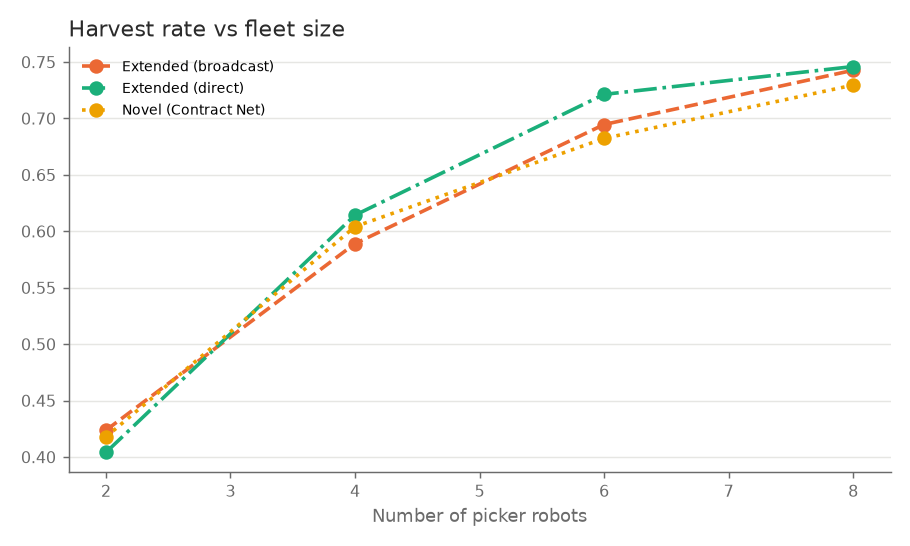

In [5]:
sweep_path = os.path.join(RESULTS, "sweep_pickers.csv")
if os.path.exists(sweep_path):
    sweep = pd.read_csv(sweep_path)
    display(sweep.groupby(["Config", "Pickers"])["Harvest rate"].mean().unstack().round(3))
    display(Image(os.path.join(RESULTS, "sweep_pickers.png")))
else:
    print("Run `python experiments.py --sweep` to generate the sweep.")

## 5. Critical analysis

**Basic vs the communicating modes.** Basic mode reaches a 100% harvest rate, but only because its
crops never age: nothing can rot, and the mission ends once the initial ~70 strawberries are home.
The cost is efficiency. Pickers wander at random, so a strawberry waits about **155 steps** to be
picked (±38 between seeds) and each one costs about **17 energy units**. With drone signals, latency
falls to about **58 steps** and energy per strawberry to **about 6**, roughly a 3× gain on both.
The drones' hovering in Basic mode helps little, because pickers have no way to sense it.

**Broadcast vs direct messaging.** Broadcast sends every picker to every crop area. Several robots
often drive to the same patch and arrive to find it already picked. That wasted travel shows up as
the highest energy per strawberry of the ageing modes (6.69) and the lowest harvest rate (0.58).
Direct messaging gives each area to one robot, raising the harvest rate to **0.62** and lowering
energy to **5.81**, with slightly fewer messages.

**Contract Net (novel mode).** Allocation by auction performs **on par with direct messaging**
(harvest 0.61, energy 5.87), but not better. Its delivery count is the least variable between seeds
(std 20.8 vs 26.4), and latency varies least (std 2.5 vs 5.1), so behaviour is more predictable.
The price is roughly **9× more messages** (≈850 vs ≈93), because every task needs a call for
proposals, one bid per picker and an award. Contract Net earns that overhead when robots differ: in
battery, load or committed work. The bids weigh all three, whereas the direct heuristic only looks
at distance and queue length. On this small, homogeneous farm those factors rarely change the
winner, which explains the tie.

**The dominant factor is fleet size, not coordination.** In every ageing mode, 30–40% of
strawberries rot. The sweep shows the harvest rate climbing from about 0.42 with 2 pickers to about
0.74 with 8, with diminishing returns after 6. Better coordination is worth about 4 percentage
points; two extra pickers are worth about 10. To an operator, the KPI says: buy pickers first, then
use targeted (direct or auction) messaging rather than broadcast.

**Limitations.** The battery and energy figures are abstract units, not watts. Drones are assumed to
know where the pickers are (fleet telemetry) when they choose a recipient for a direct message. The
urgency score stands in for a computer-vision model. Each configuration has only 10 seeds, so
differences of 1–2 points between direct and Contract Net are within one standard deviation and
should not be over-interpreted.